# Using historical network traffic data, apply time series forecasting methods (like ARIMA or Prophet) to predict potential DDoS attacks. 	

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [2]:
# Create simple sample network traffic dataset
np.random.seed(42)

dates = pd.date_range(start='2026-01-01', periods=100, freq='H')
traffic = np.random.normal(loc=120, scale=20, size=100).astype(int)

# Add artificial DDoS-like spikes
traffic[40] = 650
traffic[70] = 720

data = pd.DataFrame({
    'timestamp': dates,
    'traffic_volume': traffic
})

data.to_csv('network_traffic.csv', index=False)
data.head()

C:\Users\bhuva\AppData\Local\Temp\ipykernel_10768\3880300966.py:4: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start='2026-01-01', periods=100, freq='H')


,timestamp,traffic_volume
0,2026-01-01 00:00:00,129
1,2026-01-01 01:00:00,117
2,2026-01-01 02:00:00,132
3,2026-01-01 03:00:00,150
4,2026-01-01 04:00:00,115


In [3]:
# Load dataset
data = pd.read_csv('network_traffic.csv')
data['timestamp'] = pd.to_datetime(data['timestamp'])
data.set_index('timestamp', inplace=True)

data.head()

,traffic_volume
timestamp,
2026-01-01 00:00:00,129
2026-01-01 01:00:00,117
2026-01-01 02:00:00,132
2026-01-01 03:00:00,150
2026-01-01 04:00:00,115


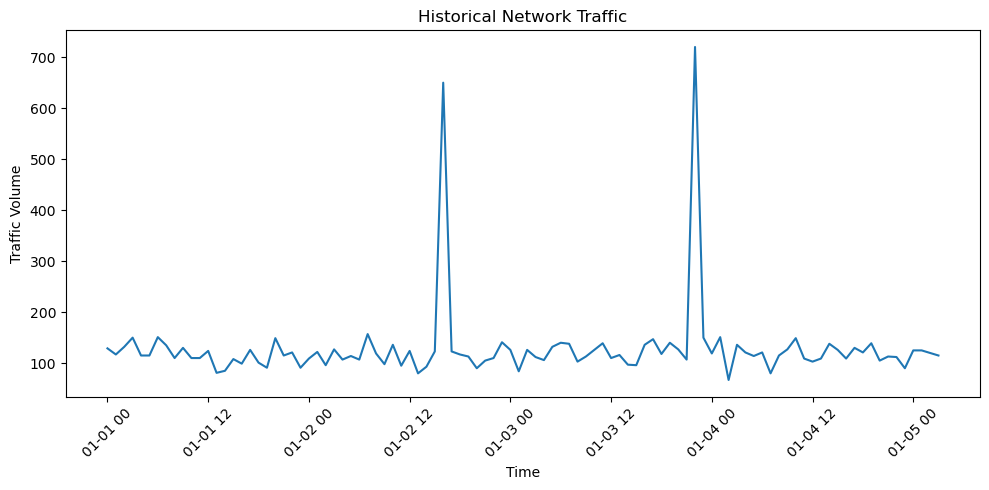

In [4]:
# Plot historical network traffic
plt.figure(figsize=(10, 5))
plt.plot(data.index, data['traffic_volume'])
plt.title('Historical Network Traffic')
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
# Train ARIMA model
model = ARIMA(data['traffic_volume'], order=(2, 1, 2))
model_fit = model.fit()

c:\Users\bhuva\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\bhuva\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\bhuva\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


In [6]:
# Forecast next 10 hours
forecast_steps = 10
forecast = model_fit.forecast(steps=forecast_steps)

future_dates = pd.date_range(
    start=data.index[-1] + pd.Timedelta(hours=1),
    periods=forecast_steps,
    freq='H'
)

forecast_df = pd.DataFrame({
    'timestamp': future_dates,
    'forecasted_traffic': forecast.values
})

forecast_df

C:\Users\bhuva\AppData\Local\Temp\ipykernel_10768\4164348224.py:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  future_dates = pd.date_range(


,timestamp,forecasted_traffic
0,2026-01-05 04:00:00,128.195899
1,2026-01-05 05:00:00,128.892310
2,2026-01-05 06:00:00,128.189445
3,2026-01-05 07:00:00,128.685667
4,2026-01-05 08:00:00,128.338547
5,2026-01-05 09:00:00,128.581297
6,2026-01-05 10:00:00,128.411537
7,2026-01-05 11:00:00,128.530254
8,2026-01-05 12:00:00,128.447233
9,2026-01-05 13:00:00,128.505291


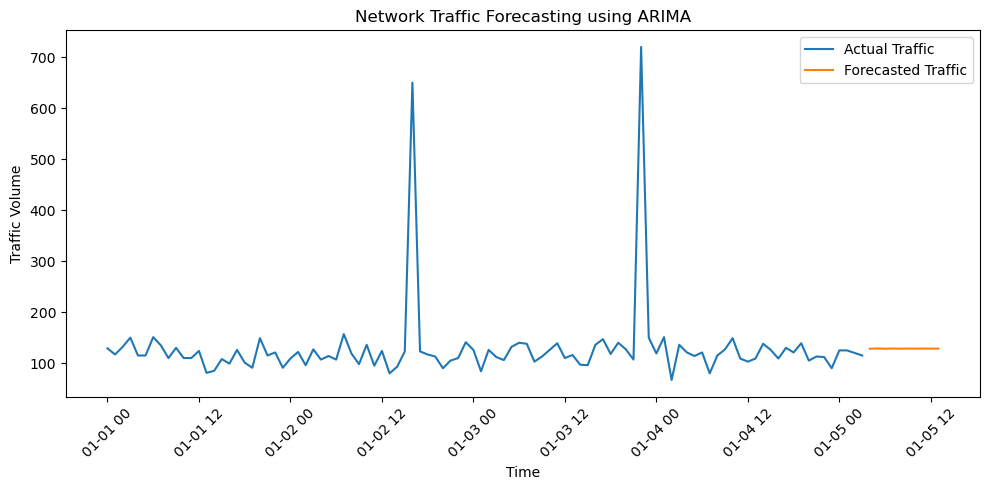

In [7]:
# Plot actual and forecasted traffic
plt.figure(figsize=(10, 5))
plt.plot(data.index, data['traffic_volume'], label='Actual Traffic')
plt.plot(forecast_df['timestamp'], forecast_df['forecasted_traffic'], label='Forecasted Traffic')
plt.title('Network Traffic Forecasting using ARIMA')
plt.xlabel('Time')
plt.ylabel('Traffic Volume')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# Detect possible DDoS attack based on threshold
threshold = 500

forecast_df['status'] = forecast_df['forecasted_traffic'].apply(
    lambda x: 'Possible DDoS Attack' if x > threshold else 'Normal Traffic'
)

forecast_df

,timestamp,forecasted_traffic,status
0,2026-01-05 04:00:00,128.195899,Normal Traffic
1,2026-01-05 05:00:00,128.892310,Normal Traffic
2,2026-01-05 06:00:00,128.189445,Normal Traffic
3,2026-01-05 07:00:00,128.685667,Normal Traffic
4,2026-01-05 08:00:00,128.338547,Normal Traffic
5,2026-01-05 09:00:00,128.581297,Normal Traffic
6,2026-01-05 10:00:00,128.411537,Normal Traffic
7,2026-01-05 11:00:00,128.530254,Normal Traffic
8,2026-01-05 12:00:00,128.447233,Normal Traffic
9,2026-01-05 13:00:00,128.505291,Normal Traffic


In [9]:
# Print alerts
for _, row in forecast_df.iterrows():
    print(row['timestamp'], '-', row['status'])

2026-01-05 04:00:00 - Normal Traffic
2026-01-05 05:00:00 - Normal Traffic
2026-01-05 06:00:00 - Normal Traffic
2026-01-05 07:00:00 - Normal Traffic
2026-01-05 08:00:00 - Normal Traffic
2026-01-05 09:00:00 - Normal Traffic
2026-01-05 10:00:00 - Normal Traffic
2026-01-05 11:00:00 - Normal Traffic
2026-01-05 12:00:00 - Normal Traffic
2026-01-05 13:00:00 - Normal Traffic
